<a href="https://colab.research.google.com/github/BrunoCapron/ESQ724-fundamentos_aprendizado_maquina/blob/main/Regularizacao/Lasso_Ridge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Regularização em Modelos de Regressão (Ridge e Lasso)

Neste notebook, vamos simular um cenário clássico de **overfitting** ajustando um polinômio de grau 15 a poucos dados ruidosos e observar como a regularização **L2 (Ridge)** e **L1 (Lasso)** controlam a magnitude dos parâmetros e melhoram a generalização.

#Setup e Geração dos Dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

# 1. Gerar dados sintéticos (função cosseno com ruído aleatório)
np.random.seed(42)
X = np.sort(np.random.uniform(0, 1, 40)).reshape(-1, 1)
y_real = np.cos(1.5 * np.pi * X).ravel()
y = y_real + np.random.normal(0, 0.25, size=X.shape[0])

# Divisão em treino (26 amostras) e teste (14 amostras)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.35, random_state=42
)

print(f"Amostras de treino: {len(X_train)} | Amostras de teste: {len(X_test)}")

Amostras de treino: 26 | Amostras de teste: 14


#Treinamento e Comparação de Métricas e Pesos

In [2]:
# Usaremos grau 15 para criar 15 features polinomiais (alta complexidade)
grau = 15

# Note o uso de StandardScaler antes da regressão regularizada
modelos = {
    "Sem Regularização (OLS)": make_pipeline(
        PolynomialFeatures(grau, include_bias=False),
        StandardScaler(),
        LinearRegression()
    ),
    "Ridge (L2, alpha=0.1)": make_pipeline(
        PolynomialFeatures(grau, include_bias=False),
        StandardScaler(),
        Ridge(alpha=0.1)
    ),
    "Lasso (L1, alpha=0.01)": make_pipeline(
        PolynomialFeatures(grau, include_bias=False),
        StandardScaler(),
        Lasso(alpha=0.01, max_iter=10000, random_state=42)
    )
}

resultados = []
coeficientes = {}

for nome, pipeline in modelos.items():
    pipeline.fit(X_train, y_train)

    y_pred_train = pipeline.predict(X_train)
    y_pred_test = pipeline.predict(X_test)

    mse_train = mean_squared_error(y_train, y_pred_train)
    mse_test = mean_squared_error(y_test, y_pred_test)

    # Extrair os 15 coeficientes aprendidos pelo modelo final
    w = pipeline.steps[-1][1].coef_
    coeficientes[nome] = w
    pesos_zerados = np.sum(np.isclose(w, 0, atol=1e-4))

    resultados.append({
        "Modelo": nome,
        "MSE Treino": round(mse_train, 4),
        "MSE Teste": round(mse_test, 4),
        "Maior Peso |w|": f"{np.max(np.abs(w)):,.2f}",
        "Pesos Zerados (de 15)": pesos_zerados
    })

df_comparacao = pd.DataFrame(resultados)
display(df_comparacao)

,Modelo,MSE Treino,MSE Teste,Maior Peso |w|,Pesos Zerados (de 15)
0,Sem Regularização (OLS),0.0241,0.0919,"986,596,331.05",0
1,"Ridge (L2, alpha=0.1)",0.0401,0.0522,0.81,0
2,"Lasso (L1, alpha=0.01)",0.0521,0.0477,1.06,12


#Visualização 1: O Ajuste das Curvas (Overfitting vs. Generalização)

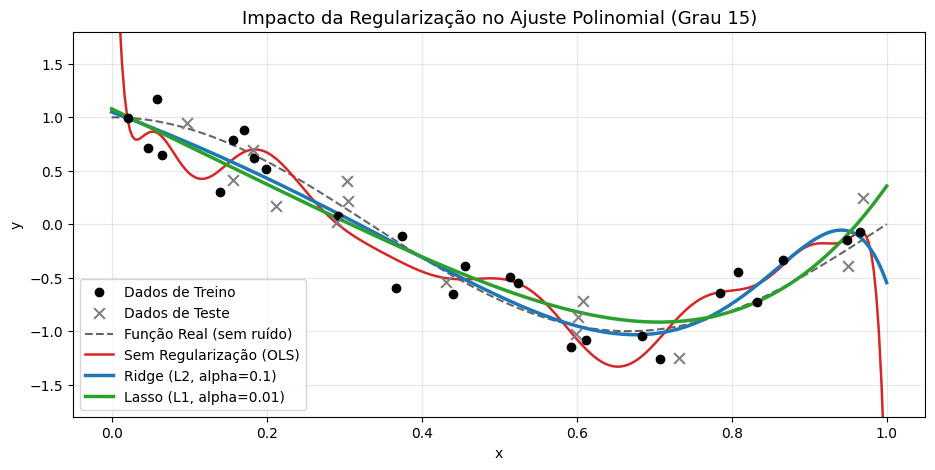

In [3]:
X_plot = np.linspace(0, 1, 300).reshape(-1, 1)

plt.figure(figsize=(11, 5))
plt.scatter(X_train, y_train, color="black", label="Dados de Treino", zorder=4)
plt.scatter(X_test, y_test, color="gray", marker="x", s=60, label="Dados de Teste", zorder=4)
plt.plot(X_plot, np.cos(1.5 * np.pi * X_plot), "k--", alpha=0.6, label="Função Real (sem ruído)")

estilos = {
    "Sem Regularização (OLS)": ("#d62728", "-", 1.8),
    "Ridge (L2, alpha=0.1)": ("#1f77b4", "-", 2.5),
    "Lasso (L1, alpha=0.01)": ("#2ca02c", "-", 2.5),
}

for nome, pipeline in modelos.items():
    cor, estilo, largura = estilos[nome]
    plt.plot(
        X_plot,
        pipeline.predict(X_plot),
        color=cor,
        linestyle=estilo,
        linewidth=largura,
        label=nome
    )

plt.ylim(-1.8, 1.8)
plt.title("Impacto da Regularização no Ajuste Polinomial (Grau 15)", fontsize=13)
plt.xlabel("x")
plt.ylabel("y")
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.show()

#Visualização 2: O que Acontece com os Coeficientes ($w$)?

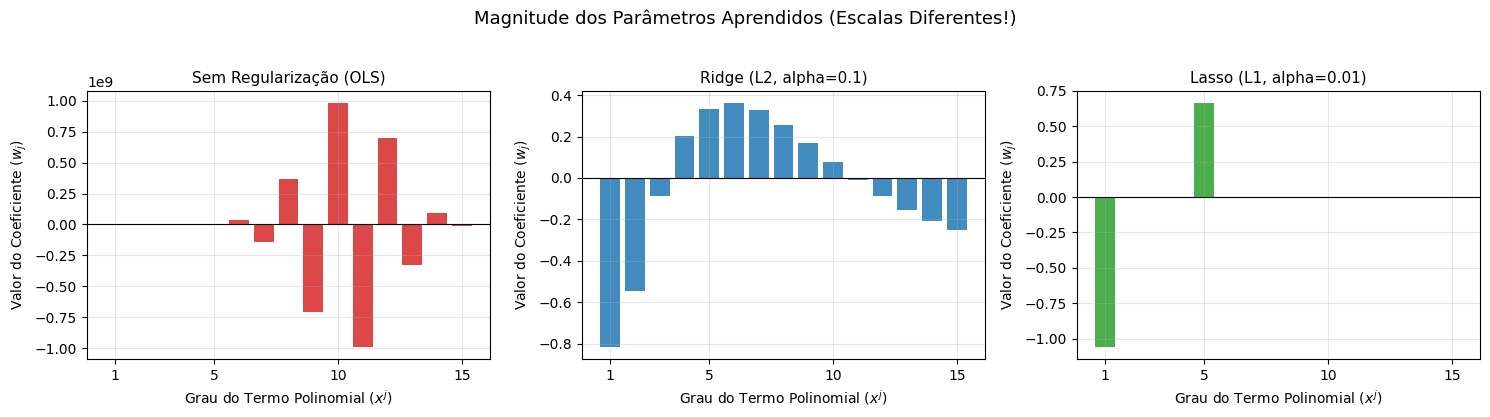

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
features_idx = np.arange(1, grau + 1)

cores = ["#d62728", "#1f77b4", "#2ca02c"]

for ax, (nome, w), cor in zip(axes, coeficientes.items(), cores):
    ax.bar(features_idx, w, color=cor, alpha=0.85)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(nome, fontsize=11)
    ax.set_xlabel("Grau do Termo Polinomial ($x^j$)")
    ax.set_ylabel("Valor do Coeficiente ($w_j$)")
    ax.set_xticks([1, 5, 10, 15])
    ax.grid(alpha=0.3)

plt.suptitle("Magnitude dos Parâmetros Aprendidos (Escalas Diferentes!)", fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

Demonstração Interativa: Variando o Hiperparâmetro $\alpha$

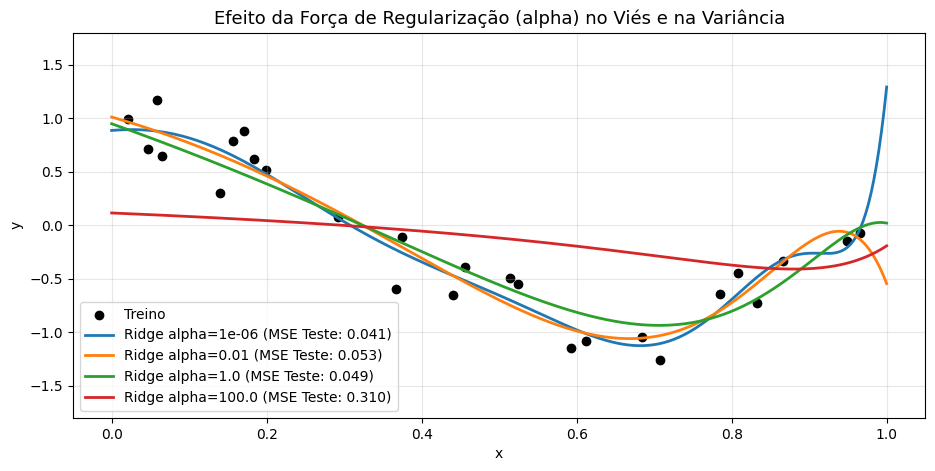

In [5]:
# Mostra a transição entre Overfitting (alpha muito pequeno) e Underfitting (alpha muito grande)
alphas = [1e-6, 0.01, 1.0, 100.0]

plt.figure(figsize=(11, 5))
plt.scatter(X_train, y_train, color="black", label="Treino")

for alpha in alphas:
    modelo_ridge = make_pipeline(
        PolynomialFeatures(grau, include_bias=False),
        StandardScaler(),
        Ridge(alpha=alpha)
    )
    modelo_ridge.fit(X_train, y_train)
    mse_t = mean_squared_error(y_test, modelo_ridge.predict(X_test))
    plt.plot(X_plot, modelo_ridge.predict(X_plot), linewidth=2, label=f"Ridge alpha={alpha} (MSE Teste: {mse_t:.3f})")

plt.ylim(-1.8, 1.8)
plt.title("Efeito da Força de Regularização (alpha) no Viés e na Variância", fontsize=13)
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.3)
plt.show()